# 1. Linear Regression: Predicting Car Fuel Efficiency (Auto MPG)

**Dataset documentation:** https://archive.ics.uci.edu/dataset/9/auto+mpg
**Data file:** `data/mpg.csv` (the UCI Auto MPG data, 398 cars, 1970-1982)

## 1.1 Objectives (Business Understanding)

**Business problem:** Imagine a car importer or a fleet buyer who wants a rough idea of how fuel efficient a car is just from its specification, before paying for road tests. Fuel use affects running costs and emissions rules, so a decent early estimate is useful.

**What I am predicting:** the miles per gallon of a car, and which specs matter most for it.

**Target variable:** `mpg` (continuous).
**Predictors:** cylinders, displacement, horsepower, weight, acceleration, model year and origin (USA / Europe / Japan).
**What counts as success:** a test RMSE of about 3 mpg or lower and an R² above 0.8 on data the model has not seen. I also want to check if adding a polynomial term gives a better model.

## 1.2 Data Exploration (Data Understanding & Preparation)

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

os.makedirs('plots', exist_ok=True)
df = pd.read_csv('data/mpg.csv')
print(df.shape)
df.head()

(398, 9)


,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,name
0,18.0,8,307.0,130.0,3504,12.0,70,usa,chevrolet chevelle malibu
1,15.0,8,350.0,165.0,3693,11.5,70,usa,buick skylark 320
2,18.0,8,318.0,150.0,3436,11.0,70,usa,plymouth satellite
3,16.0,8,304.0,150.0,3433,12.0,70,usa,amc rebel sst
4,17.0,8,302.0,140.0,3449,10.5,70,usa,ford torino


In [2]:
df.info()
print('\nMissing values per column:')
print(df.isna().sum()[df.isna().sum() > 0])
df.describe().round(2)

<class 'pandas.DataFrame'>
RangeIndex: 398 entries, 0 to 397
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   mpg           398 non-null    float64
 1   cylinders     398 non-null    int64  
 2   displacement  398 non-null    float64
 3   horsepower    392 non-null    float64
 4   weight        398 non-null    int64  
 5   acceleration  398 non-null    float64
 6   model_year    398 non-null    int64  
 7   origin        398 non-null    str    
 8   name          398 non-null    str    
dtypes: float64(4), int64(3), str(2)
memory usage: 28.1 KB

Missing values per column:
horsepower    6
dtype: int64


,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year
count,398.00,398.00,398.00,392.00,398.00,398.00,398.00
mean,23.51,5.45,193.43,104.47,2970.42,15.57,76.01
std,7.82,1.70,104.27,38.49,846.84,2.76,3.70
min,9.00,3.00,68.00,46.00,1613.00,8.00,70.00
25%,17.50,4.00,104.25,75.00,2223.75,13.82,73.00
50%,23.00,4.00,148.50,93.50,2803.50,15.50,76.00
75%,29.00,8.00,262.00,126.00,3608.00,17.18,79.00
max,46.60,8.00,455.00,230.00,5140.00,24.80,82.00


**What I see:** there are 398 cars and 9 columns. Only `horsepower` has missing values (6 rows, about 1.5%), so I fill them with the median instead of throwing rows away. `name` is basically a different label for every car, so it is no use as a predictor and I drop it. `mpg` goes from 9 to 46.6 with an average of 23.5.

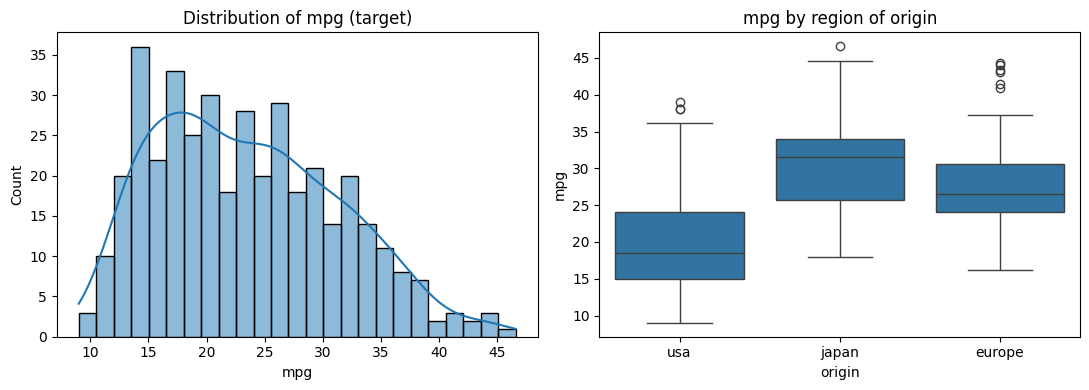

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
sns.histplot(df['mpg'], bins=25, kde=True, ax=ax[0])
ax[0].set_title('Distribution of mpg (target)')
sns.boxplot(data=df, x='origin', y='mpg', ax=ax[1])
ax[1].set_title('mpg by region of origin')
plt.tight_layout(); plt.savefig('plots/1_mpg_distribution.png', dpi=120); plt.show()

**What I see:** `mpg` is a little right-skewed (skew about 0.46). Most cars are between 15 and 30 mpg, so I don't think a transformation is needed. The boxplot shows a clear difference by origin: US cars average around 20 mpg, European cars around 28 and Japanese cars around 30. So origin looks worth keeping.

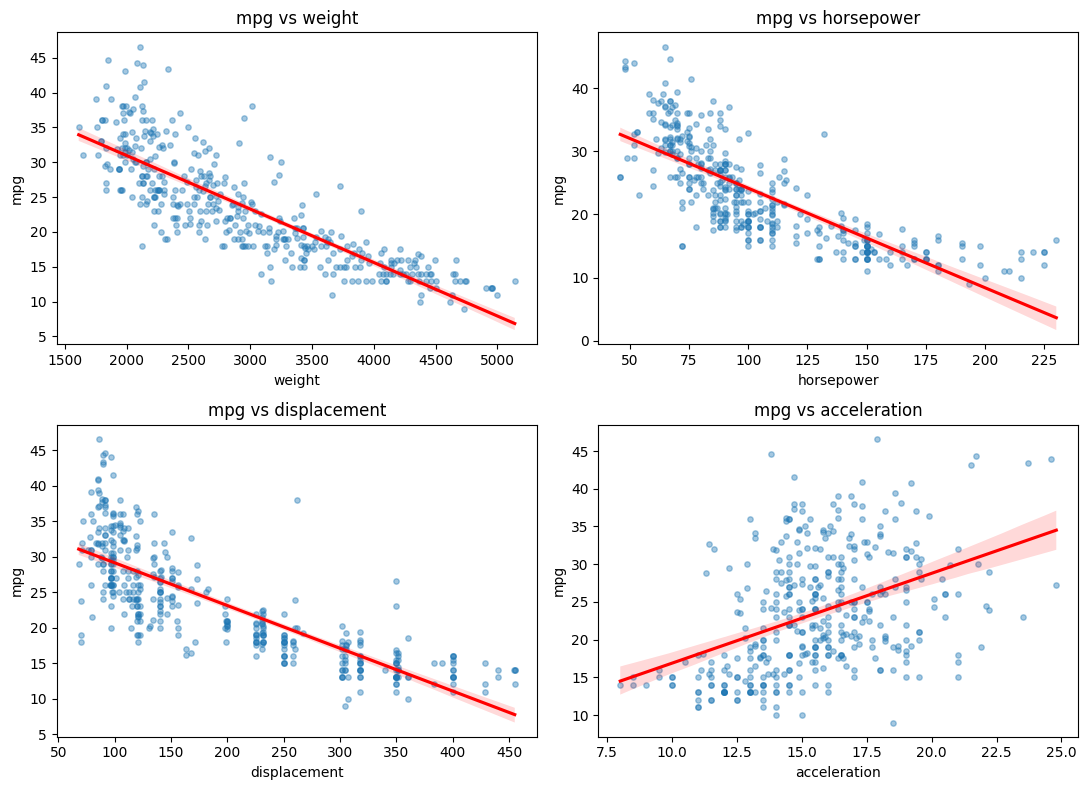

In [4]:
fig, ax = plt.subplots(2, 2, figsize=(11, 8))
for a, col in zip(ax.ravel(), ['weight', 'horsepower', 'displacement', 'acceleration']):
    sns.regplot(data=df, x=col, y='mpg', ax=a, scatter_kws={'alpha': 0.4, 's': 15}, line_kws={'color': 'red'})
    a.set_title(f'mpg vs {col}')
plt.tight_layout(); plt.savefig('plots/1_scatter_mpg_vs_features.png', dpi=120); plt.show()

**What I see:** heavier cars and cars with more horsepower or bigger engines get fewer mpg, which is what I expected. The `weight` plot is not really a straight line though. The points sit above the red line at both ends and below it in the middle, so it is curved. That is the reason I want to try a squared term later. `acceleration` only has a weak positive link with mpg.

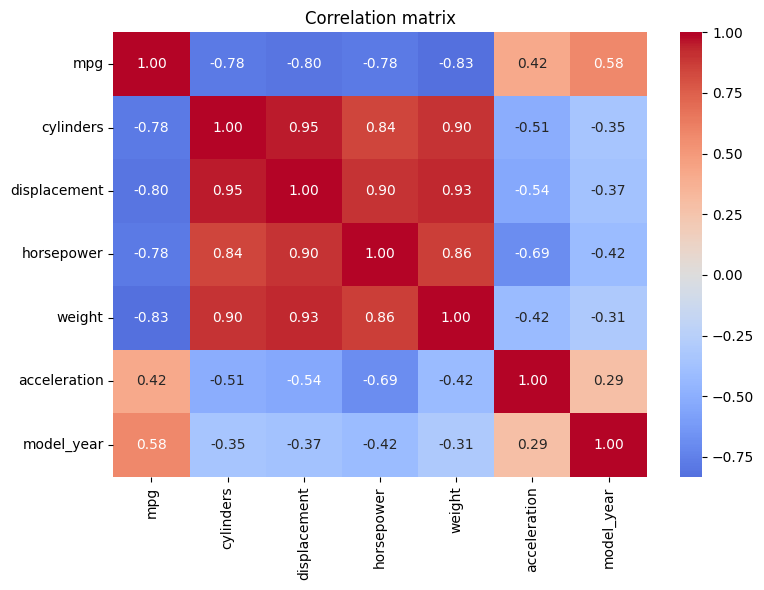

In [5]:
plt.figure(figsize=(8, 6))
sns.heatmap(df.drop(columns=['name', 'origin']).corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Correlation matrix')
plt.tight_layout(); plt.savefig('plots/1_correlation_heatmap.png', dpi=120); plt.show()

**What I see:** `weight` (-0.83), `displacement` (-0.80), `cylinders` (-0.78) and `horsepower` (-0.77) are all strongly negatively correlated with `mpg`. They are also highly correlated with each other (weight and displacement are 0.93), so multicollinearity is going to be an issue. It should not hurt the predictions much, but it makes single coefficients harder to trust. `model_year` (+0.58) shows that cars got more efficient over the years.

**Data preparation:** I fill the 6 missing horsepower values with the median, drop `name` (it is just a label, not a predictor) and one-hot encode `origin`.

In [6]:
df['horsepower'] = df['horsepower'].fillna(df['horsepower'].median())
df = df.drop(columns='name')
df = pd.get_dummies(df, columns=['origin'], drop_first=True, dtype=int)
df.head()

,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin_japan,origin_usa
0,18.0,8,307.0,130.0,3504,12.0,70,0,1
1,15.0,8,350.0,165.0,3693,11.5,70,0,1
2,18.0,8,318.0,150.0,3436,11.0,70,0,1
3,16.0,8,304.0,150.0,3433,12.0,70,0,1
4,17.0,8,302.0,140.0,3449,10.5,70,0,1


## 1.3 Modeling

In [7]:
# Define X and y, then split (random_state fixed so results can be replicated)
X = df.drop(columns='mpg')
y = df['mpg']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print('Train:', X_train.shape, ' Test:', X_test.shape)

results = {}
def evaluate(name, model, cols, Xtr=None, Xte=None):
    Xtr = X_train if Xtr is None else Xtr
    Xte = X_test if Xte is None else Xte
    cv_r2 = cross_val_score(model, Xtr[cols], y_train, cv=5, scoring='r2')
    cv_rmse = -cross_val_score(model, Xtr[cols], y_train, cv=5, scoring='neg_root_mean_squared_error')
    model.fit(Xtr[cols], y_train)
    pred = model.predict(Xte[cols])
    results[name] = {'CV R2': cv_r2.mean(), 'CV RMSE': cv_rmse.mean(),
                     'Test R2': r2_score(y_test, pred),
                     'Test RMSE': np.sqrt(mean_squared_error(y_test, pred))}
    return model, pred

Train: (318, 8)  Test: (80, 8)


### Model 1: simple linear regression (weight only)

In [8]:
m1, pred1 = evaluate('1: weight only', LinearRegression(), ['weight'])
print('Intercept:', round(m1.intercept_, 2), '  Coefficient (weight):', round(m1.coef_[0], 5))

Intercept: 46.78   Coefficient (weight): -0.00781


### Model 2: multiple linear regression (all features)

In [9]:
all_cols = list(X.columns)
m2, pred2 = evaluate('2: all features', LinearRegression(), all_cols)
coefs = pd.Series(m2.coef_, index=all_cols).round(4)
print('Intercept:', round(m2.intercept_, 2))
coefs

Intercept: -18.91


cylinders      -0.1657
displacement    0.0198
horsepower     -0.0146
weight         -0.0070
acceleration    0.0680
model_year      0.8260
origin_japan   -0.2758
origin_usa     -2.9469
dtype: float64

**Reading Model 2:** model year has the biggest effect, each newer year adds about 0.83 mpg. Each extra 100 lb of weight costs about 0.7 mpg. Compared with European cars (the reference group), US cars are about 2.9 mpg lower. The coefficients for displacement and cylinders are tiny or have a surprising sign, which I think is because they are so correlated with weight and horsepower. So I would not read those two on their own.

### Polynomial term: is it appropriate?
The weight scatter plot above is curved, so I want to test a squared term. I add `weight_sq` (weight in 1000s of lbs, squared) and keep everything else the same.

In [10]:
Xtr_p, Xte_p = X_train.copy(), X_test.copy()
for d in (Xtr_p, Xte_p):
    d['weight_k'] = d['weight'] / 1000          # weight in 1000 lbs keeps coefficients readable
    d['weight_sq'] = d['weight_k'] ** 2

# Model 3: simple polynomial regression (weight + weight^2)
m3, pred3 = evaluate('3: weight + weight^2', LinearRegression(), ['weight_k', 'weight_sq'], Xtr_p, Xte_p)
print('Model 3  intercept:', round(m3.intercept_, 2), ' coefs [weight_k, weight_sq]:', m3.coef_.round(3))

# Model 4: all features + weight^2
poly_cols = all_cols + ['weight_sq']
m4, pred4 = evaluate('4: all features + weight^2', LinearRegression(), poly_cols, Xtr_p, Xte_p)
print('Model 4  coefficient on weight_sq:', round(pd.Series(m4.coef_, index=poly_cols)['weight_sq'], 3))

Model 3  intercept: 62.39  coefs [weight_k, weight_sq]: [-18.409   1.668]
Model 4  coefficient on weight_sq: 2.277


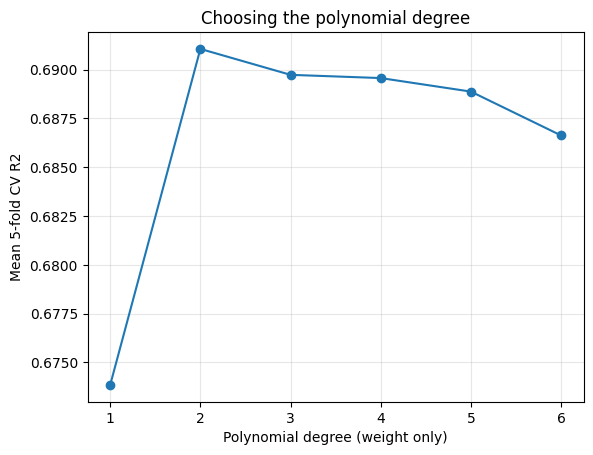

[np.float64(0.674), np.float64(0.691), np.float64(0.69), np.float64(0.69), np.float64(0.689), np.float64(0.687)]


In [11]:
# How does CV R2 change with polynomial degree on weight alone?
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import make_pipeline
degs = range(1, 7)
scores = [cross_val_score(make_pipeline(PolynomialFeatures(d, include_bias=False), LinearRegression()),
                          X_train[['weight']] / 1000, y_train, cv=5, scoring='r2').mean() for d in degs]
plt.plot(list(degs), scores, marker='o'); plt.xlabel('Polynomial degree (weight only)'); plt.ylabel('Mean 5-fold CV R2')
plt.title('Choosing the polynomial degree'); plt.grid(alpha=.3)
plt.savefig('plots/1_poly_degree.png', dpi=120); plt.show()
print([round(s, 3) for s in scores])

**Is polynomial regression appropriate?** I think yes, but only a small one. With weight alone, CV R² goes from 0.674 (straight line) to about 0.691 at degree 2, and then it stays flat or gets slightly worse for higher degrees. So the curve is real, a quadratic is enough to capture it, and higher degrees only add complexity. I stay with degree 2.

## 1.4 Evaluation & Conclusion

In [12]:
res = pd.DataFrame(results).T.round(3)
res

,CV R2,CV RMSE,Test R2,Test RMSE
1: weight only,0.674,4.476,0.723,3.859
2: all features,0.805,3.460,0.845,2.888
3: weight + weight^2,0.691,4.343,0.755,3.626
4: all features + weight^2,0.840,3.122,0.882,2.521


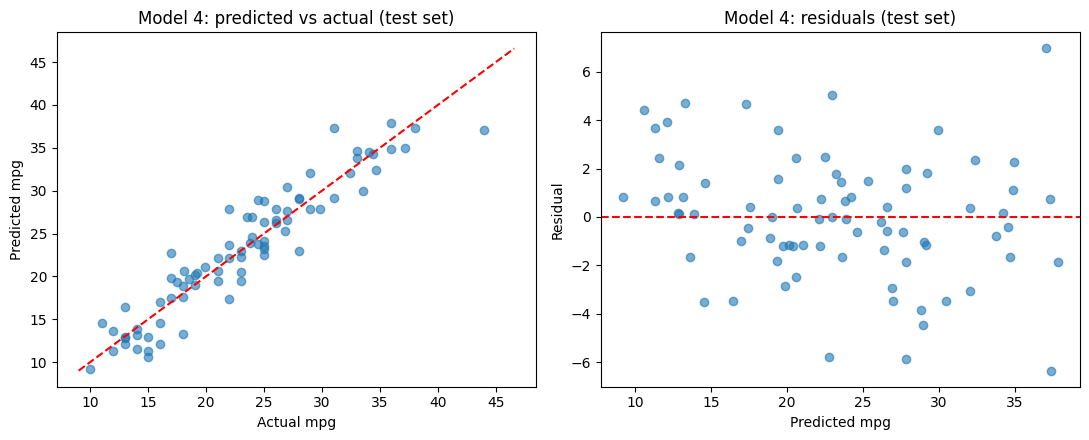

In [13]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
ax[0].scatter(y_test, pred4, alpha=.6); ax[0].plot([y.min(), y.max()], [y.min(), y.max()], 'r--')
ax[0].set_xlabel('Actual mpg'); ax[0].set_ylabel('Predicted mpg'); ax[0].set_title('Model 4: predicted vs actual (test set)')
ax[1].scatter(pred4, y_test - pred4, alpha=.6); ax[1].axhline(0, color='r', ls='--')
ax[1].set_xlabel('Predicted mpg'); ax[1].set_ylabel('Residual'); ax[1].set_title('Model 4: residuals (test set)')
plt.tight_layout(); plt.savefig('plots/1_best_model_diagnostics.png', dpi=120); plt.show()

### Evaluation
| Model | CV R² | Test R² | Test RMSE (mpg) |
|---|---|---|---|
| 1: weight only | 0.674 | 0.723 | 3.86 |
| 2: all features | 0.805 | 0.845 | 2.89 |
| 3: weight + weight² | 0.691 | 0.755 | 3.63 |
| 4: all features + weight² | **0.840** | **0.882** | **2.52** |

**About the plots:** on the test set the predicted values sit close to the red diagonal. The residuals have no obvious pattern around zero, but they spread out a bit more for low-mpg (heavy) cars, so the model is a little less reliable there.

### Conclusion
- The squared weight term helped in both cases. For the simple model test R² went from 0.72 to 0.76, and for the full model from 0.85 to 0.88 (CV R² from 0.805 to 0.840). The positive `weight_sq` coefficient means the mpg lost per extra pound gets smaller for very heavy cars.
- Model 4 meets my objective. It predicts mpg to within about 2.5 mpg (RMSE) on unseen cars and explains about 88% of the variance. CV and test results are close, so I don't think it is overfitted.
- Limitations: the data is from 1970 to 1982, so I would not use it for modern cars. Because of collinearity I would only trust model year and origin coefficients individually. The test set is only 80 cars, so the test numbers are a bit noisy.